# 🥘 SousChef AI — Standalone Testing & Evaluation Notebook

This is a **separate Kaggle/Jupyter notebook** that rebuilds the real `SousChef AI v2` pipeline from your uploaded `souschef-1.ipynb`, then runs functional and evaluation tests. You **do not** need to open the original notebook to run this one.

**Attach in Kaggle → Add Input → Datasets:**

- **Food.com Recipes and User Interactions** by Shuyang Li (`RAW_recipes.csv` and `RAW_interactions.csv`)
- **Recipe Ingredients Dataset** / **What's Cooking?** (`train.json`), for cuisine classification

**Then turn on Internet and choose Run All.** Model downloads are required on the first run. For fast smoke testing, this notebook uses **5,000 recipes**; to report final model metrics, increase to **20,000** or more and rerun.

### What the tests measure

Dataset integrity, embedding/FAISS readiness, semantic search, recommendation filters, cross-encoder reranking, collaborative filtering, source-backed RAG, cuisine classification, and offline retrieval metrics. The final report distinguishes PASS, FAIL, WARNING, and SKIP. An LLM API call is **not needed** for these tests.

**Important:** This is a fresh model build in the testing notebook, *not* an independent test of a trained model checkpoint from another Kaggle session. The retrieval benchmark is a self-retrieval proxy rather than a human-labeled recommendation-quality benchmark. Results should be described accordingly.

## 0. Install dependencies

In [1]:
%pip -q install sentence-transformers faiss-cpu ipywidgets openai

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.8/18.8 MB 65.9 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.


## 1. Initialize the real SousChef source modules

### Original SousChef module: imports and original configuration

This cell is copied **unchanged** from your uploaded `souschef-1.ipynb`; it initializes the real code being tested.

In [2]:
import os
import re
import ast
import glob
import json
import math
import hashlib
import warnings
from pathlib import Path
from collections import defaultdict

import numpy as np
import pandas as pd

from scipy.sparse import csr_matrix

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    classification_report,
    accuracy_score,
    f1_score,
    confusion_matrix,
)
from sklearn.decomposition import TruncatedSVD

import matplotlib.pyplot as plt
import plotly.express as px

warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 140)

RANDOM_STATE = 42

# Start with 20K while developing. Increase to 50K+ for the final Kaggle version.
MAX_RECIPES = 20_000
MAX_INTERACTIONS = 500_000
RAG_RECIPE_CHUNKS = 3_000

EMBEDDING_MODEL = "sentence-transformers/all-MiniLM-L6-v2"
RERANKER_MODEL = "cross-encoder/ms-marco-MiniLM-L-6-v2"

CACHE_DIR = Path("/kaggle/working/souschef_cache") if Path("/kaggle/working").exists() else Path("./souschef_cache")
CACHE_DIR.mkdir(parents=True, exist_ok=True)

print("Cache directory:", CACHE_DIR)

Cache directory: /kaggle/working/souschef_cache


### Testing configuration

Change `TEST_MAX_RECIPES` to `20_000` when running the full evaluation. A subset is faster, but its metrics are not the full-dataset metrics.

In [3]:
# Keep these settings explicit and visible for reproducibility.
TEST_MAX_RECIPES = 5_000        # Increase to 20_000 for closer comparison to your original notebook.
TEST_MAX_INTERACTIONS = 300_000 # Increase to 500_000 for final checks.
TEST_RAG_RECIPE_CHUNKS = 1_000
RUN_CROSS_ENCODER_TEST = True
RUN_OPTIONAL_LLM_TEST = False  # Intentionally disabled: no API keys or paid calls required.

MAX_RECIPES = TEST_MAX_RECIPES
MAX_INTERACTIONS = TEST_MAX_INTERACTIONS
RAG_RECIPE_CHUNKS = TEST_RAG_RECIPE_CHUNKS
print('Testing recipe limit:', MAX_RECIPES)
print('Testing interaction limit:', MAX_INTERACTIONS)

Testing recipe limit: 5000
Testing interaction limit: 300000


### Original SousChef module: Food.com file loading

This cell is copied **unchanged** from your uploaded `souschef-1.ipynb`; it initializes the real code being tested.

In [4]:
def find_file(patterns):
    search_roots = [
        Path("."),
        Path.cwd(),
        Path.cwd().parent,
        Path("/kaggle/working"),
        Path("/kaggle/input"),
    ]

    matches = []
    for root in search_roots:
        if root.exists():
            for pattern in patterns:
                matches.extend(glob.glob(str(root / "**" / pattern), recursive=True))

    matches = [
        m for m in matches
        if ".ipynb_checkpoints" not in m
        and "/notebooks/" not in m.lower()
    ]
    return matches[0] if matches else None


def safe_parse_list(x):
    if isinstance(x, list):
        return x
    if x is None or (not isinstance(x, (list, tuple)) and pd.isna(x)):
        return []
    if isinstance(x, str):
        try:
            parsed = ast.literal_eval(x)
            if isinstance(parsed, list):
                return parsed
        except Exception:
            pass
        return [i.strip() for i in x.split(",") if i.strip()]
    return list(x) if isinstance(x, (tuple, set)) else []


def build_fallback_recipe_data():
    print("⚠ No external recipe dataset found — using tiny fallback data.")
    return pd.DataFrame([
        {
            "recipe_id": 1,
            "name": "Tomato Garlic Pasta",
            "minutes": 25,
            "ingredients": "['pasta','tomato','garlic','olive oil','basil','salt']",
            "steps": "['boil pasta','cook garlic','add tomato','combine']",
            "tags": "['vegetarian','italian','quick']",
        },
        {
            "recipe_id": 2,
            "name": "Chickpea Curry",
            "minutes": 35,
            "ingredients": "['chickpeas','onion','tomato','garlic','ginger','cumin','coriander']",
            "steps": "['saute onion','add spices','add tomato','simmer chickpeas']",
            "tags": "['vegetarian','indian','high protein']",
        },
        {
            "recipe_id": 3,
            "name": "Vegetable Fried Rice",
            "minutes": 20,
            "ingredients": "['rice','carrot','peas','soy sauce','garlic','spring onion']",
            "steps": "['stir fry vegetables','add rice','season']",
            "tags": "['vegetarian','asian','quick']",
        },
    ])


def load_data(max_recipes=MAX_RECIPES, max_interactions=MAX_INTERACTIONS):
    recipe_file = find_file(["RAW_recipes.csv", "recipes.csv", "sample_recipes.csv"])
    interaction_file = find_file(["RAW_interactions.csv", "interactions.csv", "reviews.csv"])

    print("Recipe file:", recipe_file)
    print("Interaction file:", interaction_file)

    if recipe_file is None:
        recipes = build_fallback_recipe_data()
    else:
        recipes = pd.read_csv(recipe_file, nrows=max_recipes)

    if "id" in recipes.columns and "recipe_id" not in recipes.columns:
        recipes = recipes.rename(columns={"id": "recipe_id"})

    if "recipe_id" not in recipes.columns:
        recipes["recipe_id"] = np.arange(len(recipes))

    for col in ["name", "ingredients", "steps", "tags"]:
        if col not in recipes.columns:
            recipes[col] = ""

    if "minutes" not in recipes.columns:
        recipes["minutes"] = np.nan

    interactions = pd.DataFrame(columns=["user_id", "recipe_id", "rating", "date"])

    if interaction_file is not None:
        try:
            header = pd.read_csv(interaction_file, nrows=0).columns.tolist()
            desired = [c for c in ["user_id", "recipe_id", "rating", "date"] if c in header]
            interactions = pd.read_csv(
                interaction_file,
                usecols=desired,
                nrows=max_interactions
            )

            if "rating" in interactions.columns:
                interactions["rating"] = pd.to_numeric(interactions["rating"], errors="coerce")
        except Exception as e:
            print("Could not load interactions:", e)

    # Aggregate real Food.com ratings into recipe table.
    if len(interactions) and {"recipe_id", "rating"}.issubset(interactions.columns):
        rated = interactions[interactions["rating"] > 0].copy()
        agg = (
            rated.groupby("recipe_id")
            .agg(rating=("rating", "mean"), review_count=("rating", "size"))
            .reset_index()
        )
        recipes = recipes.drop(columns=["rating", "review_count"], errors="ignore")
        recipes = recipes.merge(agg, on="recipe_id", how="left")
    else:
        if "rating" not in recipes.columns:
            recipes["rating"] = np.nan
        if "review_count" not in recipes.columns:
            recipes["review_count"] = 0

    recipes["rating"] = pd.to_numeric(recipes["rating"], errors="coerce").fillna(0)
    recipes["review_count"] = pd.to_numeric(recipes["review_count"], errors="coerce").fillna(0)
    recipes["minutes"] = pd.to_numeric(recipes["minutes"], errors="coerce")

    return recipes, interactions


recipes, interactions = load_data()

print("\nRecipes:", recipes.shape)
print("Interactions:", interactions.shape)
recipes.head(3)

Recipe file: /kaggle/input/datasets/shuyangli94/food-com-recipes-and-user-interactions/RAW_recipes.csv
Interaction file: /kaggle/input/datasets/shuyangli94/food-com-recipes-and-user-interactions/RAW_interactions.csv

Recipes: (5000, 14)
Interactions: (300000, 4)


,name,recipe_id,minutes,contributor_id,submitted,tags,nutrition,n_steps,steps,description,ingredients,n_ingredients,rating,review_count
0,arriba baked winter squash mexican style,137739,55,47892,2005-09-16,"['60-minutes-or-less', 'time-to-make', 'course', 'main-ingredient', 'cuisine', 'preparation', 'occasion', 'north-american', 'side-dishes...","[51.5, 0.0, 13.0, 0.0, 2.0, 0.0, 4.0]",11,"['make a choice and proceed with recipe', 'depending on size of squash , cut into half or fourths', 'remove seeds', 'for spicy squash , ...","autumn is my favorite time of year to cook! this recipe \r\ncan be prepared either spicy or sweet, your choice!\r\ntwo of my posted mexi...","['winter squash', 'mexican seasoning', 'mixed spice', 'honey', 'butter', 'olive oil', 'salt']",7,0.000000,0.0
1,a bit different breakfast pizza,31490,30,26278,2002-06-17,"['30-minutes-or-less', 'time-to-make', 'course', 'main-ingredient', 'cuisine', 'preparation', 'occasion', 'north-american', 'breakfast',...","[173.4, 18.0, 0.0, 17.0, 22.0, 35.0, 1.0]",9,"['preheat oven to 425 degrees f', 'press dough into the bottom and sides of a 12 inch pizza pan', 'bake for 5 minutes until set but not ...",this recipe calls for the crust to be prebaked a bit before adding ingredients. feel free to change sausage to ham or bacon. this warms ...,"['prepared pizza crust', 'sausage patty', 'eggs', 'milk', 'salt and pepper', 'cheese']",6,4.666667,3.0
2,all in the kitchen chili,112140,130,196586,2005-02-25,"['time-to-make', 'course', 'preparation', 'main-dish', 'chili', 'crock-pot-slow-cooker', 'dietary', 'equipment', '4-hours-or-less']","[269.8, 22.0, 32.0, 48.0, 39.0, 27.0, 5.0]",6,"['brown ground beef in large pot', 'add chopped onions to ground beef when almost brown and sautee until wilted', 'add all other ingredi...",this modified version of 'mom's' chili was a hit at our 2004 christmas party. we made an extra large pot to have some left to freeze but...,"['ground beef', 'yellow onions', 'diced tomatoes', 'tomato paste', 'tomato soup', 'rotel tomatoes', 'kidney beans', 'water', 'chili powd...",13,0.000000,0.0


### Original SousChef module: cleaning, dietary heuristics and Bayesian rating

This cell is copied **unchanged** from your uploaded `souschef-1.ipynb`; it initializes the real code being tested.

In [5]:
def normalize_text(text):
    if text is None or (not isinstance(text, (list, tuple)) and pd.isna(text)):
        return ""
    text = str(text).lower()
    text = re.sub(r"[^a-z0-9\s\-]", " ", text)
    return re.sub(r"\s+", " ", text).strip()


def clean_list_items(items):
    items = safe_parse_list(items)
    cleaned = []
    for item in items:
        x = normalize_text(item)
        if x:
            cleaned.append(x)
    return cleaned


MEAT_TERMS = set(
    "chicken beef pork lamb turkey bacon sausage ham fish shrimp tuna salmon anchovy meat duck".split()
)
DAIRY_EGG_TERMS = set(
    "milk cheese butter cream yogurt egg paneer parmesan feta mozzarella ghee".split()
)
GLUTEN_TERMS = set(
    "wheat flour bread pasta tortilla noodles couscous barley semolina".split()
)


def contains_any(text, terms):
    text = normalize_text(text)
    return any(re.search(r"\b" + re.escape(t) + r"\b", text) for t in terms)


def bayesian_rating(rating, count, global_mean, prior_count):
    return (
        (count / (count + prior_count)) * rating
        + (prior_count / (count + prior_count)) * global_mean
    )


def add_clean_features(df):
    df = df.copy()

    df["ingredients_list"] = df["ingredients"].apply(clean_list_items)
    df["steps_list"] = df["steps"].apply(clean_list_items)
    df["tags_list"] = df["tags"].apply(clean_list_items)

    df["ingredient_text"] = df["ingredients_list"].apply(" ".join)
    df["step_text"] = df["steps_list"].apply(" ".join)
    df["tag_text"] = df["tags_list"].apply(" ".join)

    df["recipe_text"] = (
        df["name"].fillna("").astype(str)
        + " ingredients "
        + df["ingredient_text"]
        + " tags "
        + df["tag_text"]
        + " instructions "
        + df["step_text"]
    ).apply(normalize_text)

    df["is_vegetarian"] = ~df["ingredient_text"].apply(lambda x: contains_any(x, MEAT_TERMS))
    df["is_vegan"] = (
        df["is_vegetarian"]
        & ~df["ingredient_text"].apply(lambda x: contains_any(x, DAIRY_EGG_TERMS))
    )
    df["is_gluten_free"] = ~df["ingredient_text"].apply(lambda x: contains_any(x, GLUTEN_TERMS))

    df["ingredient_count"] = df["ingredients_list"].apply(len)
    df["step_count"] = df["steps_list"].apply(len)

    # Treat extreme/invalid times as missing for recommendation purposes.
    clean_minutes = df["minutes"].where(df["minutes"].between(1, 1440))
    median_minutes = clean_minutes.median() if clean_minutes.notna().any() else 30
    df["minutes_clean"] = clean_minutes.fillna(median_minutes)

    rated = df[df["rating"] > 0]
    global_mean = rated["rating"].mean() if len(rated) else 4.0
    positive_counts = df.loc[df["review_count"] > 0, "review_count"]
    prior_count = float(positive_counts.quantile(0.75)) if len(positive_counts) else 10.0
    prior_count = max(prior_count, 10.0)

    df["bayesian_rating"] = bayesian_rating(
        df["rating"],
        df["review_count"],
        global_mean,
        prior_count
    )

    if "cuisine" not in df.columns:
        df["cuisine"] = "unknown"

    return df


recipes = add_clean_features(recipes)

print("Clean recipes:", recipes.shape)
print("Mean rating prior:", round(recipes.loc[recipes.rating > 0, "rating"].mean(), 3))
recipes[
    [
        "recipe_id",
        "name",
        "minutes_clean",
        "rating",
        "review_count",
        "bayesian_rating",
        "is_vegetarian",
        "is_vegan",
    ]
].head()

Clean recipes: (5000, 29)
Mean rating prior: 4.569


,recipe_id,name,minutes_clean,rating,review_count,bayesian_rating,is_vegetarian,is_vegan
0,137739,arriba baked winter squash mexican style,55.0,0.000000,0.0,4.568550,True,False
1,31490,a bit different breakfast pizza,30.0,4.666667,3.0,4.591192,False,False
2,112140,all in the kitchen chili,130.0,0.000000,0.0,4.568550,False,False
3,59389,alouette potatoes,45.0,4.500000,2.0,4.557125,True,False
4,44061,amish tomato ketchup for canning,190.0,0.000000,0.0,4.568550,True,True


### Original SousChef module: ingredient matching and exclusions

This cell is copied **unchanged** from your uploaded `souschef-1.ipynb`; it initializes the real code being tested.

In [6]:
def parse_user_ingredients(text):
    return [
        normalize_text(i)
        for i in re.split(r"[,\n]+", str(text))
        if normalize_text(i)
    ]


def ingredient_overlap(user_ingredients, recipe_ingredients):
    user_set = set(user_ingredients)
    recipe_set = set(recipe_ingredients)

    if not recipe_set:
        return 0.0, [], []

    matched = sorted(user_set.intersection(recipe_set))
    missing = sorted(recipe_set.difference(user_set))

    # Fraction of the recipe's ingredient list already available.
    score = len(matched) / max(len(recipe_set), 1)
    return score, matched, missing


def violates_exclusions(recipe_ingredients, excluded):
    if not excluded:
        return False
    text = " ".join(recipe_ingredients)
    return any(re.search(r"\b" + re.escape(x) + r"\b", text) for x in excluded)


# Quick test
ingredient_overlap(
    parse_user_ingredients("tomato, garlic, rice, onion"),
    recipes.iloc[0]["ingredients_list"]
)

(0.0,
 [],
 ['butter',
  'honey',
  'mexican seasoning',
  'mixed spice',
  'olive oil',
  'salt',
  'winter squash'])

### Original SousChef module: SentenceTransformer embeddings and FAISS index

This cell is copied **unchanged** from your uploaded `souschef-1.ipynb`; it initializes the real code being tested.

In [7]:
class RecipeEmbeddingIndex:
    def __init__(self, df, model_name=EMBEDDING_MODEL, cache_dir=CACHE_DIR):
        self.df = df.reset_index(drop=True)
        self.texts = self.df["recipe_text"].tolist()
        self.model_name = model_name
        self.cache_dir = Path(cache_dir)

        signature_text = (
            str(len(self.df))
            + "|"
            + "|".join(self.df["recipe_id"].astype(str).head(200).tolist())
            + "|"
            + model_name
        )
        self.signature = hashlib.md5(signature_text.encode()).hexdigest()[:12]

        self.emb_path = self.cache_dir / f"recipe_embeddings_{self.signature}.npy"
        self.faiss_path = self.cache_dir / f"recipe_index_{self.signature}.faiss"

        self.model = None
        self.embeddings = None
        self.index = None
        self.faiss_enabled = False

    def build(self):
        from sentence_transformers import SentenceTransformer

        self.model = SentenceTransformer(self.model_name)

        if self.emb_path.exists():
            self.embeddings = np.load(self.emb_path)
            print("Loaded cached embeddings:", self.emb_path)
        else:
            self.embeddings = self.model.encode(
                self.texts,
                batch_size=64,
                show_progress_bar=True,
                normalize_embeddings=True,
            )
            self.embeddings = np.asarray(self.embeddings, dtype="float32")
            np.save(self.emb_path, self.embeddings)
            print("Saved embeddings:", self.emb_path)

        try:
            import faiss

            if self.faiss_path.exists():
                self.index = faiss.read_index(str(self.faiss_path))
                print("Loaded cached FAISS index:", self.faiss_path)
            else:
                self.index = faiss.IndexFlatIP(self.embeddings.shape[1])
                self.index.add(self.embeddings)
                faiss.write_index(self.index, str(self.faiss_path))
                print("Saved FAISS index:", self.faiss_path)

            self.faiss_enabled = True

        except Exception as e:
            from sklearn.neighbors import NearestNeighbors

            print("FAISS unavailable; using sklearn fallback:", e)
            self.index = NearestNeighbors(metric="cosine")
            self.index.fit(self.embeddings)
            self.faiss_enabled = False

        return self

    def encode_query(self, query):
        q = self.model.encode([query], normalize_embeddings=True)
        return np.asarray(q, dtype="float32")

    def search(self, query, top_k=10):
        top_k = min(top_k, len(self.df))
        q = self.encode_query(query)

        if self.faiss_enabled:
            scores, idx = self.index.search(q, top_k)
            return idx[0], scores[0]

        distances, idx = self.index.kneighbors(q, n_neighbors=top_k)
        return idx[0], 1 - distances[0]


recipe_index = RecipeEmbeddingIndex(recipes).build()

print("Recipes indexed:", len(recipes))
print("FAISS enabled:", recipe_index.faiss_enabled)

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

...

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/79 [00:00<?, ?it/s]

Saved embeddings: /kaggle/working/souschef_cache/recipe_embeddings_937cada74b28.npy
Saved FAISS index: /kaggle/working/souschef_cache/recipe_index_937cada74b28.faiss
Recipes indexed: 5000
FAISS enabled: True


### Original SousChef module: semantic search and cross-encoder

This cell is copied **unchanged** from your uploaded `souschef-1.ipynb`; it initializes the real code being tested.

In [8]:
_cross_encoder = None


def get_cross_encoder():
    global _cross_encoder

    if _cross_encoder is None:
        from sentence_transformers import CrossEncoder
        print("Loading cross-encoder reranker...")
        _cross_encoder = CrossEncoder(RERANKER_MODEL)

    return _cross_encoder


def minmax_array(values):
    values = np.asarray(values, dtype=float)
    if len(values) == 0:
        return values
    if np.nanmax(values) == np.nanmin(values):
        return np.ones(len(values)) * 0.5
    return (values - np.nanmin(values)) / (np.nanmax(values) - np.nanmin(values))


def semantic_recipe_search(query, top_k=8, candidate_k=50, use_reranker=False):
    idx, scores = recipe_index.search(query, top_k=max(top_k, candidate_k))

    result = recipes.iloc[idx].copy().reset_index(drop=True)
    result["semantic_score"] = scores

    if use_reranker and len(result):
        model = get_cross_encoder()
        pairs = [(query, t) for t in result["recipe_text"].tolist()]
        cross_scores = model.predict(pairs, batch_size=32, show_progress_bar=False)
        result["rerank_score"] = minmax_array(cross_scores)
        result = result.sort_values("rerank_score", ascending=False)
    else:
        result["rerank_score"] = minmax_array(result["semantic_score"].values)

    return result.head(top_k)


semantic_recipe_search(
    "quick vegetarian dinner with tomato garlic rice",
    top_k=5,
    use_reranker=False,
)[
    ["name", "minutes_clean", "rating", "review_count", "semantic_score", "rerank_score"]
]

,name,minutes_clean,rating,review_count,semantic_score,rerank_score
0,add an ingredient risotto,40.0,0.0,0.0,0.662858,1.000000
1,2 5 challenge friendly real pasta sauce,45.0,0.0,0.0,0.655736,0.926116
2,absolutely fabulous roasted vegetetables,58.0,5.0,1.0,0.638155,0.743717
3,absolutely delicious and simple tomato basil and garlic pasta,23.0,0.0,0.0,0.636624,0.727842
4,21 vegetarian sloppy joes,35.0,0.0,0.0,0.634891,0.709862


### Original SousChef module: semantic RAG and grounded answer

This cell is copied **unchanged** from your uploaded `souschef-1.ipynb`; it initializes the real code being tested.

In [9]:
CULINARY_FALLBACK = [
    {
        "source": "culinary::salty",
        "text": "For an overly salty dish, increase unsalted bulk or liquid, add starch where appropriate, and rebalance with fat or acid. Avoid trying to remove salt with sugar alone."
    },
    {
        "source": "culinary::spicy",
        "text": "To reduce excessive chile heat, add dairy when compatible, coconut milk, more base ingredients, starch, or a small amount of sweetness. Water alone can dilute flavor without balancing heat."
    },
    {
        "source": "culinary::watery_sauce",
        "text": "A watery sauce can be reduced by simmering uncovered. Depending on the dish, thicken with a starch slurry, blended vegetables, nut paste, roux, or concentrated tomato paste."
    },
    {
        "source": "culinary::split_sauce",
        "text": "A split emulsion sauce can often be rescued by lowering heat and slowly whisking the broken sauce into a small fresh base such as water, egg yolk, mustard, or cream depending on the sauce."
    },
    {
        "source": "culinary::dry_protein",
        "text": "Dry cooked protein cannot regain lost moisture internally, but serving it with sauce, broth, fat, or slicing it thinly can improve perceived juiciness. Prevent dryness by controlling final temperature."
    },
    {
        "source": "culinary::substitution_roles",
        "text": "Ingredient substitutions work best when the replacement serves the same role: fat, acid, sweetness, structure, thickening, leavening, protein, or aroma."
    },
    {
        "source": "culinary::vegan_dairy",
        "text": "Common vegan replacements include plant milks for milk, coconut cream or cashew cream for heavy cream, nutritional yeast for savory cheese notes, and plant butter for butter."
    },
    {
        "source": "culinary::baking_precision",
        "text": "Baking substitutions are less forgiving than savory cooking because flour, fat, sugar, eggs, moisture, and leavening affect structure. Change one major variable at a time where possible."
    },
]


def load_knowledge_base():
    docs = list(CULINARY_FALLBACK)

    knowledge_file = find_file(["culinary_knowledge.csv"])
    if knowledge_file:
        try:
            kb = pd.read_csv(knowledge_file)
            for _, row in kb.iterrows():
                docs.append(
                    {
                        "source": f"knowledge::{row.get('topic', 'topic')}",
                        "text": str(row.get("content", "")),
                    }
                )
        except Exception as e:
            print("Could not load culinary_knowledge.csv:", e)

    # Add recipe chunks for recipe-specific questions.
    recipe_sample = recipes.head(min(len(recipes), RAG_RECIPE_CHUNKS))
    for _, row in recipe_sample.iterrows():
        docs.append(
            {
                "source": f"recipe::{row['recipe_id']}::{row['name']}",
                "text": (
                    f"Recipe: {row['name']}. "
                    f"Ingredients: {row['ingredient_text']}. "
                    f"Instructions: {row['step_text']}. "
                    f"Tags: {row['tag_text']}."
                ),
            }
        )

    return pd.DataFrame(docs).drop_duplicates("text").reset_index(drop=True)


class SemanticKnowledgeIndex:
    def __init__(self, docs, model):
        self.docs = docs.reset_index(drop=True)
        self.model = model
        self.embeddings = None
        self.index = None
        self.faiss_enabled = False

    def build(self):
        self.embeddings = self.model.encode(
            self.docs["text"].tolist(),
            batch_size=64,
            show_progress_bar=True,
            normalize_embeddings=True,
        )
        self.embeddings = np.asarray(self.embeddings, dtype="float32")

        try:
            import faiss
            self.index = faiss.IndexFlatIP(self.embeddings.shape[1])
            self.index.add(self.embeddings)
            self.faiss_enabled = True
        except Exception:
            from sklearn.neighbors import NearestNeighbors
            self.index = NearestNeighbors(metric="cosine")
            self.index.fit(self.embeddings)

        return self

    def search(self, query, top_k=5):
        top_k = min(top_k, len(self.docs))
        q = self.model.encode([query], normalize_embeddings=True)
        q = np.asarray(q, dtype="float32")

        if self.faiss_enabled:
            scores, idx = self.index.search(q, top_k)
            idx, scores = idx[0], scores[0]
        else:
            distances, idx = self.index.kneighbors(q, n_neighbors=top_k)
            idx, scores = idx[0], 1 - distances[0]

        out = self.docs.iloc[idx].copy()
        out["score"] = scores
        return out.reset_index(drop=True)


rag_docs = load_knowledge_base()
rag_index = SemanticKnowledgeIndex(rag_docs, recipe_index.model).build()

print("RAG documents:", len(rag_docs))
print("RAG FAISS enabled:", rag_index.faiss_enabled)


def retrieve_knowledge(question, top_k=5):
    return rag_index.search(question, top_k=top_k)


def grounded_local_answer(question, top_k=5):
    evidence = retrieve_knowledge(question, top_k=top_k)

    lines = [
        "I retrieved the following evidence that is most relevant to your question:",
        "",
    ]

    for i, row in evidence.iterrows():
        text = row["text"]
        # Keep local mode extractive/grounded instead of pretending to be an LLM.
        short = text[:420] + ("..." if len(text) > 420 else "")
        lines.append(f"[S{i+1}] {short}")

    lines += [
        "",
        "Use these retrieved suggestions as the basis for the cooking decision.",
        "For food-safety-sensitive questions, verify safe temperatures and handling guidance from an authoritative source.",
    ]

    return "\n".join(lines), evidence


def get_secret(name):
    # Works with Kaggle Secrets if configured; otherwise environment variable.
    try:
        from kaggle_secrets import UserSecretsClient
        value = UserSecretsClient().get_secret(name)
        if value:
            return value
    except Exception:
        pass
    return os.getenv(name)


def llm_rag_answer(question, top_k=5):
    evidence = retrieve_knowledge(question, top_k=top_k)
    api_key = get_secret("OPENAI_API_KEY")

    if not api_key:
        local, _ = grounded_local_answer(question, top_k=top_k)
        return (
            "OPENAI_API_KEY is not configured, so SousChef is showing grounded retrieval instead.\n\n"
            + local,
            evidence,
        )

    context = "\n\n".join(
        f"[S{i+1}] Source: {row.source}\n{row.text}"
        for i, row in enumerate(evidence.itertuples())
    )

    prompt = f'''
You are SousChef AI, a practical cooking copilot.

Use the retrieved evidence below as your factual basis.
Do not invent recipe facts that are absent from the evidence.
When you use a retrieved fact, cite the source marker such as [S1].
If the evidence is insufficient, clearly say what is uncertain.
For food-safety-sensitive questions, add a short safety caveat.

EVIDENCE
{context}

USER QUESTION
{question}

Return:
1. A concise direct answer.
2. Practical steps.
3. A short "Why this works" explanation.
'''

    try:
        from openai import OpenAI

        client = OpenAI(api_key=api_key)
        model_name = os.getenv("OPENAI_MODEL", "gpt-4o-mini")

        response = client.chat.completions.create(
            model=model_name,
            messages=[{"role": "user", "content": prompt}],
            temperature=0.2,
        )

        return response.choices[0].message.content, evidence

    except Exception as e:
        local, _ = grounded_local_answer(question, top_k=top_k)
        return f"LLM generation failed ({e}).\n\n{local}", evidence


demo_answer, demo_evidence = grounded_local_answer(
    "My curry is too spicy. How can I reduce the heat?"
)
print(demo_answer[:1500])

Batches:   0%|          | 0/16 [00:00<?, ?it/s]

RAG documents: 1008
RAG FAISS enabled: True
I retrieved the following evidence that is most relevant to your question:

[S1] Recipe: harak mas curry  sri lankan beef curry. Ingredients: stewing beef ghee onions fresh ginger garlic cloves curry powder ground turmeric black mustard seeds salt vinegar chilies tomatoes. Instructions: cut steak into 2 inch squares heat the ghee in a saucepan and gently fry the onions ginger and garlic until just beginning to turn golden add curry powder turmeric mustard seeds and fry over a low heat for 2-3 min...
[S2] Recipe: creamy  chicken curry. Ingredients: boneless skinless chicken breasts garlic cloves soy yogurt turmeric onions chicken stock cardamom pods cinnamon stick black peppercorns cloves coriander seed fresh ginger ground cumin chili powder salt freshly ground black pepper fresh coriander. Instructions: slice the chicken and place in a bowl peel and crush the garlic mix with the soya yogurt and turmeric and pour over...
[S3] Recipe: best ever

### Original SousChef module: collaborative filtering and hybrid ranking

This cell is copied **unchanged** from your uploaded `souschef-1.ipynb`; it initializes the real code being tested.

In [10]:
def normalize_series(s):
    s = pd.to_numeric(s, errors="coerce").fillna(0)
    if len(s) == 0:
        return s
    if s.max() == s.min():
        return pd.Series(np.ones(len(s)) * 0.5, index=s.index)
    return (s - s.min()) / (s.max() - s.min())


class CollaborativeRecipeModel:
    def __init__(
        self,
        interactions,
        allowed_recipe_ids,
        min_user_ratings=5,
        max_users=5000,
        max_items=10000,
        n_factors=32,
    ):
        self.interactions = interactions.copy()
        self.allowed_recipe_ids = set(allowed_recipe_ids)
        self.min_user_ratings = min_user_ratings
        self.max_users = max_users
        self.max_items = max_items
        self.n_factors = n_factors

        self.ready = False
        self.user_to_idx = {}
        self.item_to_idx = {}
        self.user_factors = None
        self.item_factors = None

    def fit(self):
        required = {"user_id", "recipe_id", "rating"}
        if not required.issubset(self.interactions.columns) or len(self.interactions) < 100:
            print("Collaborative filtering skipped: interactions unavailable.")
            return self

        df = self.interactions[
            self.interactions["recipe_id"].isin(self.allowed_recipe_ids)
            & (self.interactions["rating"] > 0)
        ].dropna(subset=["user_id", "recipe_id", "rating"]).copy()

        counts = df["user_id"].value_counts()
        keep_users = counts[counts >= self.min_user_ratings].head(self.max_users).index
        df = df[df["user_id"].isin(keep_users)]

        item_counts = df["recipe_id"].value_counts()
        keep_items = item_counts.head(self.max_items).index
        df = df[df["recipe_id"].isin(keep_items)]

        if df["user_id"].nunique() < 10 or df["recipe_id"].nunique() < 10:
            print("Collaborative filtering skipped: not enough dense interaction data.")
            return self

        users = df["user_id"].drop_duplicates().tolist()
        items = df["recipe_id"].drop_duplicates().tolist()

        self.user_to_idx = {u: i for i, u in enumerate(users)}
        self.item_to_idx = {r: i for i, r in enumerate(items)}

        # Center each user's ratings to model preference rather than rating scale.
        user_mean = df.groupby("user_id")["rating"].transform("mean")
        centered = df["rating"] - user_mean

        rows = df["user_id"].map(self.user_to_idx).to_numpy()
        cols = df["recipe_id"].map(self.item_to_idx).to_numpy()

        matrix = csr_matrix(
            (centered.to_numpy(), (rows, cols)),
            shape=(len(users), len(items)),
        )

        n_components = min(
            self.n_factors,
            max(2, min(matrix.shape) - 1),
        )

        svd = TruncatedSVD(n_components=n_components, random_state=RANDOM_STATE)
        self.user_factors = svd.fit_transform(matrix)
        self.item_factors = svd.components_.T
        self.ready = True

        print(
            f"Collaborative model ready: {len(users):,} users × "
            f"{len(items):,} recipes × {n_components} factors"
        )
        return self

    def score(self, user_id, recipe_ids):
        neutral = np.ones(len(recipe_ids), dtype=float) * 0.5

        if not self.ready or user_id not in self.user_to_idx:
            return neutral

        u = self.user_factors[self.user_to_idx[user_id]]
        raw = []

        for recipe_id in recipe_ids:
            item_idx = self.item_to_idx.get(recipe_id)
            if item_idx is None:
                raw.append(np.nan)
            else:
                raw.append(float(np.dot(u, self.item_factors[item_idx])))

        raw = np.asarray(raw, dtype=float)

        known = ~np.isnan(raw)
        if known.sum() < 2:
            return neutral

        scaled = neutral.copy()
        scaled[known] = minmax_array(raw[known])
        return scaled


cf_model = CollaborativeRecipeModel(
    interactions,
    recipes["recipe_id"].tolist(),
).fit()


def hybrid_recommend(
    user_ingredients_text,
    query="",
    diet="Any",
    max_minutes=60,
    excluded_ingredients_text="",
    user_id=None,
    top_k=10,
    use_reranker=False,
):
    user_ingredients = parse_user_ingredients(user_ingredients_text)
    excluded = parse_user_ingredients(excluded_ingredients_text)

    query_text = (query + " " + " ".join(user_ingredients)).strip()
    if not query_text:
        query_text = "easy recipe"

    candidate_count = min(300, len(recipes))
    idx, semantic_scores = recipe_index.search(query_text, top_k=candidate_count)

    candidates = recipes.iloc[idx].copy().reset_index(drop=True)
    candidates["semantic_score"] = semantic_scores

    # Hard filters first.
    candidates = candidates[candidates["minutes_clean"] <= max_minutes].copy()

    if diet == "Vegetarian":
        candidates = candidates[candidates["is_vegetarian"]]
    elif diet == "Vegan":
        candidates = candidates[candidates["is_vegan"]]
    elif diet == "Gluten-Free":
        candidates = candidates[candidates["is_gluten_free"]]

    if excluded:
        mask = candidates["ingredients_list"].apply(
            lambda x: not violates_exclusions(x, excluded)
        )
        candidates = candidates[mask].copy()

    if not len(candidates):
        return candidates

    overlap = candidates["ingredients_list"].apply(
        lambda x: ingredient_overlap(user_ingredients, x)
    )

    candidates["ingredient_score"] = overlap.apply(lambda x: x[0])
    candidates["matched_ingredients"] = overlap.apply(lambda x: ", ".join(x[1]))
    candidates["missing_ingredients"] = overlap.apply(
        lambda x: ", ".join(x[2][:12])
    )

    candidates["bayesian_score"] = normalize_series(candidates["bayesian_rating"])

    candidates["time_score"] = (
        1 - candidates["minutes_clean"] / max(max_minutes, 1)
    ).clip(0, 1)

    candidates["cf_score"] = cf_model.score(
        user_id,
        candidates["recipe_id"].tolist(),
    )

    candidates["rerank_score"] = normalize_series(candidates["semantic_score"])

    if use_reranker and len(candidates):
        rerank_n = min(60, len(candidates))
        head = candidates.head(rerank_n).copy()

        model = get_cross_encoder()
        pairs = [(query_text, t) for t in head["recipe_text"].tolist()]
        cross_scores = model.predict(
            pairs,
            batch_size=32,
            show_progress_bar=False,
        )

        candidates.loc[head.index, "rerank_score"] = minmax_array(cross_scores)

    # If no recognized user profile exists, redistribute CF weight.
    personalized = cf_model.ready and user_id in cf_model.user_to_idx

    if personalized:
        weights = {
            "rerank": 0.25,
            "ingredient": 0.25,
            "bayesian": 0.15,
            "time": 0.10,
            "cf": 0.25,
        }
    else:
        weights = {
            "rerank": 0.35,
            "ingredient": 0.30,
            "bayesian": 0.20,
            "time": 0.15,
            "cf": 0.00,
        }

    candidates["final_score"] = (
        weights["rerank"] * normalize_series(candidates["rerank_score"])
        + weights["ingredient"] * candidates["ingredient_score"]
        + weights["bayesian"] * candidates["bayesian_score"]
        + weights["time"] * candidates["time_score"]
        + weights["cf"] * candidates["cf_score"]
    )

    candidates["why"] = candidates.apply(
        lambda r: (
            f"{len([x for x in r['matched_ingredients'].split(', ') if x])} ingredients matched; "
            f"{r['minutes_clean']:.0f} min; "
            f"weighted rating {r['bayesian_rating']:.2f}; "
            f"semantic relevance {r['semantic_score']:.2f}"
        ),
        axis=1,
    )

    columns = [
        "recipe_id",
        "name",
        "minutes_clean",
        "rating",
        "review_count",
        "bayesian_rating",
        "final_score",
        "ingredient_score",
        "semantic_score",
        "cf_score",
        "matched_ingredients",
        "missing_ingredients",
        "why",
    ]

    return (
        candidates.sort_values("final_score", ascending=False)
        [columns]
        .head(top_k)
        .reset_index(drop=True)
    )


hybrid_recommend(
    "tomato, garlic, rice, onion",
    query="quick vegetarian dinner",
    diet="Vegetarian",
    max_minutes=45,
    top_k=5,
)

Collaborative model ready: 152 users × 689 recipes × 32 factors


,recipe_id,name,minutes_clean,rating,review_count,bayesian_rating,final_score,ingredient_score,semantic_score,cf_score,matched_ingredients,missing_ingredients,why
0,136471,7 minute vegetable soup,30.0,0.0,0.0,4.568550,0.573548,0.333333,0.678188,0.5,"garlic, onion","dried basil, frozen mixed vegetables, tomato sauce, tomatoes",2 ingredients matched; 30 min; weighted rating 4.57; semantic relevance 0.68
1,429838,10 minute tomato sauce from america s test kitchen,10.0,0.0,0.0,4.568550,0.570521,0.111111,0.676911,0.5,onion,"butter, crushed tomatoes, dried oregano, fresh basil, garlic cloves, olive oil, salt, sugar",1 ingredients matched; 10 min; weighted rating 4.57; semantic relevance 0.68
2,136399,8 vegetable ragout,30.0,5.0,1.0,4.607772,0.549758,0.083333,0.693241,0.5,onion,"carrot, celery, corn kernel, fresh parsley, hot pepper sauce, italian stewed tomatoes, minced garlic cloves, pepper, romano beans, slice...",1 ingredients matched; 30 min; weighted rating 4.61; semantic relevance 0.69
3,148362,2 5 challenge friendly real pasta sauce,45.0,0.0,0.0,4.568550,0.520405,0.090909,0.707529,0.5,onion,"chopped tomatoes, courgette, dried herbs, garlic clove, mushrooms, olive oil, paprika, pepper, salt and pepper, sweetcorn",1 ingredients matched; 45 min; weighted rating 4.57; semantic relevance 0.71
4,308203,agourontomatosalata,15.0,0.0,0.0,4.568550,0.485492,0.000000,0.662140,0.5,,"cucumber, dried oregano, green onions, lemon juice of, olive oil, salt and pepper, tomatoes",0 ingredients matched; 15 min; weighted rating 4.57; semantic relevance 0.66


### Original SousChef module: cuisine classifier training and prediction

This cell is copied **unchanged** from your uploaded `souschef-1.ipynb`; it initializes the real code being tested.

In [11]:
def load_whats_cooking_if_available():
    train_json = find_file(["train.json"])

    if train_json is None:
        return None

    try:
        wc = pd.read_json(train_json)

        if not {"cuisine", "ingredients"}.issubset(wc.columns):
            return None

        wc["ingredient_text"] = wc["ingredients"].apply(
            lambda x: " ".join(clean_list_items(x))
        )

        return wc[["cuisine", "ingredient_text"]].dropna()

    except Exception as e:
        print("Could not load What's Cooking dataset:", e)
        return None


cuisine_df = load_whats_cooking_if_available()
cuisine_model = None
cuisine_results = pd.DataFrame()
cuisine_test = None

if cuisine_df is None or cuisine_df["cuisine"].nunique() < 2:
    print(
        "Cuisine classifier skipped. Add the Kaggle 'What's Cooking?' "
        "dataset so train.json is available."
    )

else:
    cuisine_df = cuisine_df.sample(
        min(len(cuisine_df), 30_000),
        random_state=RANDOM_STATE,
    )

    X_train, X_test, y_train, y_test = train_test_split(
        cuisine_df["ingredient_text"],
        cuisine_df["cuisine"],
        test_size=0.20,
        random_state=RANDOM_STATE,
        stratify=cuisine_df["cuisine"],
    )

    candidate_models = {
        "TFIDF + LogisticRegression": Pipeline([
            (
                "tfidf",
                TfidfVectorizer(
                    max_features=30_000,
                    ngram_range=(1, 2),
                    stop_words="english",
                ),
            ),
            (
                "clf",
                LogisticRegression(
                    max_iter=1200,
                    n_jobs=-1,
                    class_weight="balanced",
                ),
            ),
        ]),
        "TFIDF + LinearSVC": Pipeline([
            (
                "tfidf",
                TfidfVectorizer(
                    max_features=30_000,
                    ngram_range=(1, 2),
                    stop_words="english",
                ),
            ),
            (
                "clf",
                LinearSVC(class_weight="balanced"),
            ),
        ]),
    }

    result_rows = []
    fitted = {}

    for name, model in candidate_models.items():
        print("Training:", name)
        model.fit(X_train, y_train)
        pred = model.predict(X_test)

        acc = accuracy_score(y_test, pred)
        macro_f1 = f1_score(y_test, pred, average="macro")

        result_rows.append(
            {
                "model": name,
                "accuracy": acc,
                "macro_f1": macro_f1,
            }
        )
        fitted[name] = model

    cuisine_results = pd.DataFrame(result_rows).sort_values(
        "macro_f1",
        ascending=False,
    )

    best_name = cuisine_results.iloc[0]["model"]
    cuisine_model = fitted[best_name]
    cuisine_test = (X_test, y_test)

    print("\nModel comparison:")
    display(cuisine_results)

    best_pred = cuisine_model.predict(X_test)
    print("\nBest model:", best_name)
    print(classification_report(y_test, best_pred, zero_division=0))


def predict_cuisine_from_ingredients(ingredients_text):
    if cuisine_model is None:
        return (
            "Cuisine model unavailable. Attach the Kaggle "
            "'What's Cooking?' dataset."
        )

    clean_text = " ".join(parse_user_ingredients(ingredients_text))
    pred = cuisine_model.predict([clean_text])[0]

    return pred


predict_cuisine_from_ingredients(
    "tomato, garlic, cumin, coriander, chickpeas"
)

Training: TFIDF + LogisticRegression
Training: TFIDF + LinearSVC

Model comparison:


,model,accuracy,macro_f1
1,TFIDF + LinearSVC,0.776333,0.695604
0,TFIDF + LogisticRegression,0.746667,0.672436



Best model: TFIDF + LinearSVC
              precision    recall  f1-score   support

   brazilian       0.60      0.60      0.60        68
     british       0.54      0.54      0.54       123
cajun_creole       0.72      0.79      0.75       238
     chinese       0.77      0.84      0.80       401
    filipino       0.62      0.58      0.60       110
      french       0.61      0.63      0.62       409
       greek       0.70      0.72      0.71       178
      indian       0.86      0.89      0.87       461
       irish       0.50      0.54      0.52       104
     italian       0.87      0.84      0.85      1182
    jamaican       0.72      0.78      0.75        74
    japanese       0.78      0.66      0.72       215
      korean       0.75      0.73      0.74       125
     mexican       0.92      0.91      0.92       963
    moroccan       0.77      0.85      0.81       121
     russian       0.48      0.43      0.46        72
 southern_us       0.76      0.75      0.75       

'indian'

### Original SousChef module: original offline evaluations

This cell is copied **unchanged** from your uploaded `souschef-1.ipynb`; it initializes the real code being tested.

In [12]:
def evaluate_semantic_retrieval(n_samples=100, ks=(1, 5, 10)):
    eligible = recipes[recipes["ingredient_count"] >= 4]

    if len(eligible) == 0:
        return pd.DataFrame(), {}

    sample = eligible.sample(
        min(n_samples, len(eligible)),
        random_state=RANDOM_STATE,
    )

    ranks = []

    for _, row in sample.iterrows():
        ingredients = row["ingredients_list"]
        keep_n = max(2, int(len(ingredients) * 0.60))
        query_ingredients = ingredients[:keep_n]

        query = "recipe with " + ", ".join(query_ingredients)

        idx, _ = recipe_index.search(query, top_k=max(ks))
        retrieved_ids = recipes.iloc[idx]["recipe_id"].tolist()

        try:
            rank = retrieved_ids.index(row["recipe_id"]) + 1
        except ValueError:
            rank = None

        ranks.append(rank)

    metrics = {}

    for k in ks:
        metrics[f"HitRate@{k}"] = np.mean(
            [r is not None and r <= k for r in ranks]
        )

    metrics["MRR"] = np.mean(
        [1 / r if r is not None else 0 for r in ranks]
    )

    detail = pd.DataFrame({"rank": ranks})
    return detail, metrics


RAG_EVAL_SET = [
    {
        "question": "How can I fix a sauce that is too watery?",
        "expected_terms": ["watery", "simmer", "slurry"],
    },
    {
        "question": "My curry is much too spicy. What can I do?",
        "expected_terms": ["spicy", "dairy", "coconut"],
    },
    {
        "question": "How do I rescue an overly salty dish?",
        "expected_terms": ["salty", "unsalted", "starch"],
    },
    {
        "question": "What should I consider when substituting ingredients in baking?",
        "expected_terms": ["baking", "structure", "leavening"],
    },
]


def evaluate_rag_retrieval(eval_set=RAG_EVAL_SET, top_k=5):
    rows = []

    for item in eval_set:
        evidence = retrieve_knowledge(item["question"], top_k=top_k)
        expected = [normalize_text(x) for x in item["expected_terms"]]

        rank = None

        for i, text in enumerate(evidence["text"].tolist(), start=1):
            t = normalize_text(text)

            # Ground-truth document counts as found when it contains at least
            # two of the expected concepts.
            matches = sum(term in t for term in expected)

            if matches >= min(2, len(expected)):
                rank = i
                break

        rows.append(
            {
                "question": item["question"],
                "rank": rank,
                f"hit@{top_k}": rank is not None,
                "reciprocal_rank": 1 / rank if rank else 0,
            }
        )

    df = pd.DataFrame(rows)

    summary = {
        f"HitRate@{top_k}": df[f"hit@{top_k}"].mean(),
        "MRR": df["reciprocal_rank"].mean(),
    }

    return df, summary


retrieval_eval_detail, retrieval_metrics = evaluate_semantic_retrieval()
rag_eval_detail, rag_metrics = evaluate_rag_retrieval()

print("Semantic retrieval metrics:")
display(pd.DataFrame([retrieval_metrics]))

print("RAG retrieval metrics:")
display(pd.DataFrame([rag_metrics]))

display(rag_eval_detail)

Semantic retrieval metrics:


,HitRate@1,HitRate@5,HitRate@10,MRR
0,0.3,0.53,0.6,0.386095


RAG retrieval metrics:


,HitRate@5,MRR
0,0.75,0.75


,question,rank,hit@5,reciprocal_rank
0,How can I fix a sauce that is too watery?,1.0,True,1.0
1,My curry is much too spicy. What can I do?,NaN,False,0.0
2,How do I rescue an overly salty dish?,1.0,True,1.0
3,What should I consider when substituting ingredients in baking?,1.0,True,1.0


## 2. Test recorder and diagnostics

In [13]:
from IPython.display import display
from collections import OrderedDict
import traceback

TEST_RESULTS = []

def check(name, condition, detail='', *, skip=False, warning=False):
    """Log a test without interrupting later tests."""
    status = 'SKIP' if skip else ('WARN' if warning else ('PASS' if bool(condition) else 'FAIL'))
    TEST_RESULTS.append({'test': name, 'status': status, 'detail': str(detail)[:800]})
    print(f'[{status}] {name}: {detail}')
    return status

def run_test(name, fn):
    try:
        passed, detail = fn()
        return check(name, passed, detail)
    except Exception as exc:
        return check(name, False, f'{type(exc).__name__}: {exc}')

def show_results():
    frame = pd.DataFrame(TEST_RESULTS)
    display(frame)
    return frame

print('Test harness initialized. All checks will be visible in the final report.')

Test harness initialized. All checks will be visible in the final report.


## 3. Test input datasets and cleaned recipe table

In [14]:
recipe_path = find_file(['RAW_recipes.csv'])
interaction_path = find_file(['RAW_interactions.csv'])
cuisine_path = find_file(['train.json'])

check('Food.com recipe CSV connected', recipe_path is not None, recipe_path)
check('Food.com interactions CSV connected', interaction_path is not None, interaction_path)
check('Cuisine JSON connected', cuisine_path is not None, cuisine_path, skip=cuisine_path is None)
check('Nonempty recipe dataframe', len(recipes) >= 100, f'{len(recipes):,} recipes')
check('Nonempty user interactions', len(interactions) >= 100, f'{len(interactions):,} interactions')
check('Recipe IDs unique', recipes['recipe_id'].is_unique,
      f'duplicates={recipes["recipe_id"].duplicated().sum()}')
check('Parsed ingredients available', recipes['ingredient_count'].gt(0).mean() > .95,
      f'{recipes["ingredient_count"].gt(0).mean():.1%} have ingredients')
check('Recipe text available', recipes['recipe_text'].str.len().gt(5).mean() > .95,
      f'{recipes["recipe_text"].str.len().gt(5).mean():.1%} nonempty')
check('Bayesian ratings numeric', np.isfinite(recipes['bayesian_rating']).all(),
      'No NaN or infinite Bayesian ratings')
print('\nDataset summary:')
display(pd.DataFrame([{'recipes':len(recipes), 'interactions':len(interactions),
                       'vegetarian_heuristic':int(recipes.is_vegetarian.sum()),
                       'vegan_heuristic':int(recipes.is_vegan.sum())}]))

[PASS] Food.com recipe CSV connected: /kaggle/input/datasets/shuyangli94/food-com-recipes-and-user-interactions/RAW_recipes.csv
[PASS] Food.com interactions CSV connected: /kaggle/input/datasets/shuyangli94/food-com-recipes-and-user-interactions/RAW_interactions.csv
[PASS] Cuisine JSON connected: /kaggle/input/datasets/kaggle/recipe-ingredients-dataset/train.json
[PASS] Nonempty recipe dataframe: 5,000 recipes
[PASS] Nonempty user interactions: 300,000 interactions
[PASS] Recipe IDs unique: duplicates=0
[PASS] Parsed ingredients available: 100.0% have ingredients
[PASS] Recipe text available: 100.0% nonempty
[PASS] Bayesian ratings numeric: No NaN or infinite Bayesian ratings

Dataset summary:


,recipes,interactions,vegetarian_heuristic,vegan_heuristic
0,5000,300000,3483,1204


## 4. Test SentenceTransformer embeddings and semantic recipe search

In [15]:
check('Embeddings shape matches recipes',
      recipe_index.embeddings.ndim == 2 and recipe_index.embeddings.shape[0] == len(recipes),
      str(recipe_index.embeddings.shape))
check('Embedding values finite', np.isfinite(recipe_index.embeddings).all(),
      'Vector embeddings contain no NaN / inf')
check('FAISS vector search enabled', bool(recipe_index.faiss_enabled),
      'FAISS active' if recipe_index.faiss_enabled else 'NearestNeighbors fallback in use',
      warning=not recipe_index.faiss_enabled)

query_cases = [
    'quick vegetarian pasta with tomatoes and garlic',
    'chickpea curry with onions and Indian spices',
    'rice and vegetable dinner',
    'easy chocolate dessert',
]
for q in query_cases:
    try:
        idx, sims = recipe_index.search(q, top_k=5)
        good = len(idx) == 5 and np.all((idx >= 0) & (idx < len(recipes))) and np.isfinite(sims).all()
        check('Semantic search returns valid results', good, q)
        print('QUERY:', q)
        display(recipes.iloc[idx][['name', 'minutes_clean']].assign(similarity=np.round(sims,3)))
    except Exception as exc:
        check('Semantic search returns valid results', False, f'{q}: {exc}')

[PASS] Embeddings shape matches recipes: (5000, 384)
[PASS] Embedding values finite: Vector embeddings contain no NaN / inf
[PASS] FAISS vector search enabled: FAISS active
[PASS] Semantic search returns valid results: quick vegetarian pasta with tomatoes and garlic
QUERY: quick vegetarian pasta with tomatoes and garlic


,name,minutes_clean,similarity
2310,absolutely delicious and simple tomato basil and garlic pasta,23.0,0.756
1081,2 5 challenge friendly real pasta sauce,45.0,0.744
1392,30 minute pasta sauce,30.0,0.687
838,10 minute tomato sauce from america s test kitchen,10.0,0.685
4041,almost fat free spaghetti bolognese,25.0,0.683


[PASS] Semantic search returns valid results: chickpea curry with onions and Indian spices
QUERY: chickpea curry with onions and Indian spices


,name,minutes_clean,similarity
2723,african coconut curried chickpea soup,60.0,0.696
2430,achari chicken,40.0,0.649
2428,achaari chicken,30.0,0.647
405,harak mas curry sri lankan beef curry,130.0,0.640
799,1 pot curried rotini with currants peas and red peppers,15.0,0.631


[PASS] Semantic search returns valid results: rice and vegetable dinner
QUERY: rice and vegetable dinner


,name,minutes_clean,similarity
4723,amazing turkish confetti rice,35.0,0.617
2770,african rice dinner,75.0,0.610
211,i thought i had nothing to eat rice,35.0,0.608
4660,amazing mexican rice,30.0,0.595
204,healthy fried rice,25.0,0.592


[PASS] Semantic search returns valid results: easy chocolate dessert
QUERY: easy chocolate dessert


,name,minutes_clean,similarity
4075,almost instant rocky road,15.0,0.633
4748,amazingly easy chocolate buttercream frosting,15.0,0.630
4264,alton browns dairy free chocolate pie,30.0,0.614
4515,amarula and chocolate covered strawberries,30.0,0.614
1252,3 ingredient fruity chocolate mousse,20.0,0.606


## 5. Test recipe recommendations, hard filters, and personalization

In [16]:
meal = hybrid_recommend(
    user_ingredients_text='tomato, garlic, pasta, basil, olive oil',
    query='quick vegetarian Italian meal', diet='Vegetarian', max_minutes=45,
    top_k=10, use_reranker=False,
)
check('Recommender returns recipes', len(meal) > 0, f'{len(meal)} recipes')
if len(meal):
    check('Ranking is descending', meal['final_score'].is_monotonic_decreasing,
          'Sorted by final_score')
    check('Ranking scores finite', np.isfinite(meal['final_score']).all(),
          'No NaN / inf')
    by_id = recipes.set_index('recipe_id')
    check('Time filter respected',
          all(by_id.loc[r, 'minutes_clean'] <= 45 for r in meal['recipe_id']), '<=45 minutes')
    check('Vegetarian heuristic filter respected',
          all(bool(by_id.loc[r, 'is_vegetarian']) for r in meal['recipe_id']),
          'Only recipes tagged as vegetarian by notebook rules')
    display(meal[['name','final_score','matched_ingredients','missing_ingredients','why']])

exclusion_case = hybrid_recommend('rice, onion, garlic, vegetables', query='easy dinner',
                                   excluded_ingredients_text='peanut, shrimp', max_minutes=70, top_k=10)
if len(exclusion_case):
    ids = exclusion_case.recipe_id.tolist()
    ok = all(not violates_exclusions(recipes.loc[recipes.recipe_id.eq(r),'ingredients_list'].iloc[0],
                                         ['peanut','shrimp']) for r in ids)
    check('Exclusions obey current code rules', ok, 'Checks exclusion patterns used in your implementation')
else:
    check('Exclusions obey current code rules', False, 'No candidates returned', skip=True)

# This intentionally tests a known edge case: singular ingredient exclusion vs plural spelling.
plural_safe = violates_exclusions(['roasted peanuts'], ['peanut'])
check('Exclusion variant regression: peanut vs peanuts', plural_safe,
      'Current implementation may miss plural/synonym variants. Do NOT rely on this for allergy safety.',
      warning=not plural_safe)

if cf_model.ready and cf_model.user_to_idx:
    sample_uid = next(iter(cf_model.user_to_idx))
    scores = cf_model.score(sample_uid, meal.recipe_id.tolist() if len(meal) else recipes.recipe_id.head(5).tolist())
    check('Collaborative user factors return finite scores', np.isfinite(scores).all(),
          f'Known user_id example: {sample_uid}')
else:
    check('Collaborative user factors return finite scores', False,
          'No dense user profiles with this subset', skip=True)

[PASS] Recommender returns recipes: 10 recipes
[PASS] Ranking is descending: Sorted by final_score
[PASS] Ranking scores finite: No NaN / inf
[PASS] Time filter respected: <=45 minutes
[PASS] Vegetarian heuristic filter respected: Only recipes tagged as vegetarian by notebook rules


,name,final_score,matched_ingredients,missing_ingredients,why
0,absolutely delicious and simple tomato basil and garlic pasta,0.566244,olive oil,"cherry tomatoes, fresh basil leaves, fresh mozzarella cheese, garlic cloves, parmesan cheese, salt freshly ground black pepper, scallion...",1 ingredients matched; 23 min; weighted rating 4.57; semantic relevance 0.72
1,10 minute tomato sauce from america s test kitchen,0.565385,olive oil,"butter, crushed tomatoes, dried oregano, fresh basil, garlic cloves, onion, salt, sugar",1 ingredients matched; 10 min; weighted rating 4.57; semantic relevance 0.70
2,30 minute pasta sauce,0.532553,olive oil,"dried basil, dried marjoram, dried oregano, fennel seed, garlic cloves, red pepper flakes, salt, tomatoes",1 ingredients matched; 30 min; weighted rating 4.69; semantic relevance 0.68
3,aglio olio e peperoncino garlic oil and chilli pasta sauce,0.521812,,"cooked spaghetti, extra virgin olive oil, flat leaf parsley, garlic clove, red chile, salt",0 ingredients matched; 25 min; weighted rating 4.57; semantic relevance 0.72
4,almost as simple pasta with parmesan herbs and fresh garlic,0.507455,pasta,"butter, fresh herbs, garlic cloves, parmesan cheese, salt and pepper",1 ingredients matched; 17 min; weighted rating 4.73; semantic relevance 0.63
5,alla checca,0.506459,olive oil,"fresh basil leaf, garlic cloves, salt and pepper, tomatoes",1 ingredients matched; 15 min; weighted rating 4.57; semantic relevance 0.66
6,a different garlic bread,0.494262,olive oil,"french bread, garlic cloves, italian spices, mozzarella cheese, roma tomato",1 ingredients matched; 30 min; weighted rating 4.52; semantic relevance 0.70
7,5 minute spaghetti sauce,0.448366,olive oil,"fresh basil, fresh ground pepper, garlic cloves, romano cheese, salt, sugar, tomatoes",1 ingredients matched; 15 min; weighted rating 4.57; semantic relevance 0.63
8,a feel good meal,0.440783,olive oil,"black pepper, broccoli floret, cherry tomatoes, dried oregano, dried parsley, fresh basil, garlic cloves, hot red chili peppers, red bel...",1 ingredients matched; 30 min; weighted rating 4.57; semantic relevance 0.67
9,acini di pepe salad,0.436569,,"acini di pepe pasta, basil leaves, extra virgin olive oil, feta cheese, grape tomatoes, kosher salt, pine nuts, radicchio, red onion, re...",0 ingredients matched; 26 min; weighted rating 4.71; semantic relevance 0.64


[PASS] Exclusions obey current code rules: Checks exclusion patterns used in your implementation
[WARN] Exclusion variant regression: peanut vs peanuts: Current implementation may miss plural/synonym variants. Do NOT rely on this for allergy safety.
[PASS] Collaborative user factors return finite scores: Known user_id example: 6258


## 6. Test cross-encoder reranking (optional model download)

In [17]:
if RUN_CROSS_ENCODER_TEST:
    try:
        plain = semantic_recipe_search('quick tomato basil pasta dinner', top_k=8, candidate_k=25,
                                       use_reranker=False)
        crossed = semantic_recipe_search('quick tomato basil pasta dinner', top_k=8, candidate_k=25,
                                         use_reranker=True)
        valid = len(crossed) == 8 and np.isfinite(crossed['rerank_score']).all()
        check('Cross-encoder reranking executes', valid,
              'Comparison: same query, top 8 retrieved/reranked')
        display(pd.DataFrame({'FAISS_only':plain['name'].tolist(),
                              'CrossEncoder_top8':crossed['name'].tolist()}))
    except Exception as exc:
        check('Cross-encoder reranking executes', False, f'{type(exc).__name__}: {exc}')
else:
    check('Cross-encoder reranking executes', False,
          'Disabled by RUN_CROSS_ENCODER_TEST flag', skip=True)

Loading cross-encoder reranker...


config.json:   0%|          | 0.00/794 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

...

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/711k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/132 [00:00<?, ?B/s]

[PASS] Cross-encoder reranking executes: Comparison: same query, top 8 retrieved/reranked


,FAISS_only,CrossEncoder_top8
0,absolutely delicious and simple tomato basil and garlic pasta,absolutely delicious and simple tomato basil and garlic pasta
1,10 minute tomato sauce from america s test kitchen,15 minute creamy sun tomato basil cashew pasta
2,30 minute pasta sauce,4 cheese summer pasta supper
3,2 5 challenge friendly real pasta sauce,10 minute tomato sauce from america s test kitchen
4,5 minute spaghetti sauce,america s test kitchen simple cheese lasagna
5,copycat la madeline s tomato basil soup,30 minute pasta sauce
6,aglio e olio pasta garlic and oil,aglio e olio pasta garlic and oil
7,15 minute creamy sun tomato basil cashew pasta,5 minute spaghetti sauce


## 7. Test RAG evidence retrieval and grounded responses

In [18]:
rag_queries = [
    'How can I fix an overly salty soup?',
    'My curry is too spicy. What should I change?',
    'How do I thicken watery tomato sauce?',
    'What makes substitutions in baking difficult?',
]
for question in rag_queries:
    try:
        evidence = retrieve_knowledge(question, top_k=5)
        answer, local_evidence = grounded_local_answer(question, top_k=5)
        good = len(evidence) > 0 and {'source', 'text', 'score'}.issubset(evidence.columns)
        check('RAG retrieval returns attributed evidence', good, question)
        check('Grounded local output includes source markers', '[S1]' in answer,
              question)
        print('\nQUESTION:', question)
        print('ANSWER EXCERPT:', answer[:450], '...')
        display(evidence[['source','score','text']].head(3))
    except Exception as exc:
        check('RAG retrieved answer', False, f'{question}: {exc}')

if RUN_OPTIONAL_LLM_TEST:
    check('LLM test manually enabled', True,
          'Run llm_rag_answer(...) only if you deliberately configured a valid key')
else:
    check('Paid LLM generation', False, 'Skipped: avoids API charges and secret requirements', skip=True)

[PASS] RAG retrieval returns attributed evidence: How can I fix an overly salty soup?
[PASS] Grounded local output includes source markers: How can I fix an overly salty soup?

QUESTION: How can I fix an overly salty soup?
ANSWER EXCERPT: I retrieved the following evidence that is most relevant to your question:

[S1] For an overly salty dish, increase unsalted bulk or liquid, add starch where appropriate, and rebalance with fat or acid. Avoid trying to remove salt with sugar alone.
[S2] Recipe: thicker than pea soup  pea soup. Ingredients: split peas water carrots onions potatoes turnips salt pepper. Instructions: throw all the ingredients into a large pot bring to a boil then si ...


,source,score,text
0,culinary::salty,0.611369,"For an overly salty dish, increase unsalted bulk or liquid, add starch where appropriate, and rebalance with fat or acid. Avoid trying t..."
1,recipe::274988::thicker than pea soup pea soup,0.571776,Recipe: thicker than pea soup pea soup. Ingredients: split peas water carrots onions potatoes turnips salt pepper. Instructions: throw ...
2,recipe::241445::better than a baked potato soup,0.541395,Recipe: better than a baked potato soup. Ingredients: red potatoes onion celery chicken broth sour cream velveeta cheese white pepper s...


[PASS] RAG retrieval returns attributed evidence: My curry is too spicy. What should I change?
[PASS] Grounded local output includes source markers: My curry is too spicy. What should I change?

QUESTION: My curry is too spicy. What should I change?
ANSWER EXCERPT: I retrieved the following evidence that is most relevant to your question:

[S1] Recipe: harak mas curry  sri lankan beef curry. Ingredients: stewing beef ghee onions fresh ginger garlic cloves curry powder ground turmeric black mustard seeds salt vinegar chilies tomatoes. Instructions: cut steak into 2 inch squares heat the ghee in a saucepan and gently fry the onions ginger and garlic until just beginning to turn golden add curry powder turmeri ...


,source,score,text
0,recipe::305431::harak mas curry sri lankan beef curry,0.644314,Recipe: harak mas curry sri lankan beef curry. Ingredients: stewing beef ghee onions fresh ginger garlic cloves curry powder ground tur...
1,recipe::376660::best ever thai chicken curry,0.591333,Recipe: best ever thai chicken curry. Ingredients: curry onion ginger chili garlic cloves oil ground coriander ground cumin ground turm...
2,recipe::137434::creamy chicken curry,0.586659,Recipe: creamy chicken curry. Ingredients: boneless skinless chicken breasts garlic cloves soy yogurt turmeric onions chicken stock car...


[PASS] RAG retrieval returns attributed evidence: How do I thicken watery tomato sauce?
[PASS] Grounded local output includes source markers: How do I thicken watery tomato sauce?

QUESTION: How do I thicken watery tomato sauce?
ANSWER EXCERPT: I retrieved the following evidence that is most relevant to your question:

[S1] A watery sauce can be reduced by simmering uncovered. Depending on the dish, thicken with a starch slurry, blended vegetables, nut paste, roux, or concentrated tomato paste.
[S2] Recipe: tomato  sauce. Ingredients: tomato paste whole tomatoes oregano dried leaf basil onion salt pepper sugar garlic cloves olive oil. Instructions: saut garlic and onion in olive oil add ...


,source,score,text
0,culinary::watery_sauce,0.839490,"A watery sauce can be reduced by simmering uncovered. Depending on the dish, thicken with a starch slurry, blended vegetables, nut paste..."
1,recipe::340730::tomato sauce,0.533446,Recipe: tomato sauce. Ingredients: tomato paste whole tomatoes oregano dried leaf basil onion salt pepper sugar garlic cloves olive oil...
2,recipe::100870::leftovers spaghetti sauce,0.525912,Recipe: leftovers spaghetti sauce. Ingredients: stewed tomatoes prego spaghetti sauce garlic ground beef white onion granulated sugar. ...


[PASS] RAG retrieval returns attributed evidence: What makes substitutions in baking difficult?
[PASS] Grounded local output includes source markers: What makes substitutions in baking difficult?

QUESTION: What makes substitutions in baking difficult?
ANSWER EXCERPT: I retrieved the following evidence that is most relevant to your question:

[S1] Baking substitutions are less forgiving than savory cooking because flour, fat, sugar, eggs, moisture, and leavening affect structure. Change one major variable at a time where possible.
[S2] Ingredient substitutions work best when the replacement serves the same role: fat, acid, sweetness, structure, thickening, leavening, protein, or aroma.
[S3] Recipe: 100 year ol ...


,source,score,text
0,culinary::baking_precision,0.824967,"Baking substitutions are less forgiving than savory cooking because flour, fat, sugar, eggs, moisture, and leavening affect structure. C..."
1,culinary::substitution_roles,0.513044,"Ingredient substitutions work best when the replacement serves the same role: fat, acid, sweetness, structure, thickening, leavening, pr..."
2,recipe::402119::100 year old pie crust pastry dough,0.450531,Recipe: 100 year old pie crust pastry dough. Ingredients: all-purpose flour vegetable shortening white sugar salt egg cold water. Instr...


[SKIP] Paid LLM generation: Skipped: avoids API charges and secret requirements


## 8. Test cuisine classification on held-out data

[PASS] Cuisine classifier trained: 6,000 held-out recipes
[PASS] Cuisine classifier predictions valid: One label per test example
Held-out Accuracy: 0.7763
Held-out Macro-F1: 0.6956


,model,accuracy,macro_f1
1,TFIDF + LinearSVC,0.776333,0.695604
0,TFIDF + LogisticRegression,0.746667,0.672436


              precision    recall  f1-score   support

   brazilian       0.60      0.60      0.60        68
     british       0.54      0.54      0.54       123
cajun_creole       0.72      0.79      0.75       238
     chinese       0.77      0.84      0.80       401
    filipino       0.62      0.58      0.60       110
      french       0.61      0.63      0.62       409
       greek       0.70      0.72      0.71       178
      indian       0.86      0.89      0.87       461
       irish       0.50      0.54      0.52       104
     italian       0.87      0.84      0.85      1182
    jamaican       0.72      0.78      0.75        74
    japanese       0.78      0.66      0.72       215
      korean       0.75      0.73      0.74       125
     mexican       0.92      0.91      0.92       963
    moroccan       0.77      0.85      0.81       121
     russian       0.48      0.43      0.46        72
 southern_us       0.76      0.75      0.75       648
     spanish       0.52    

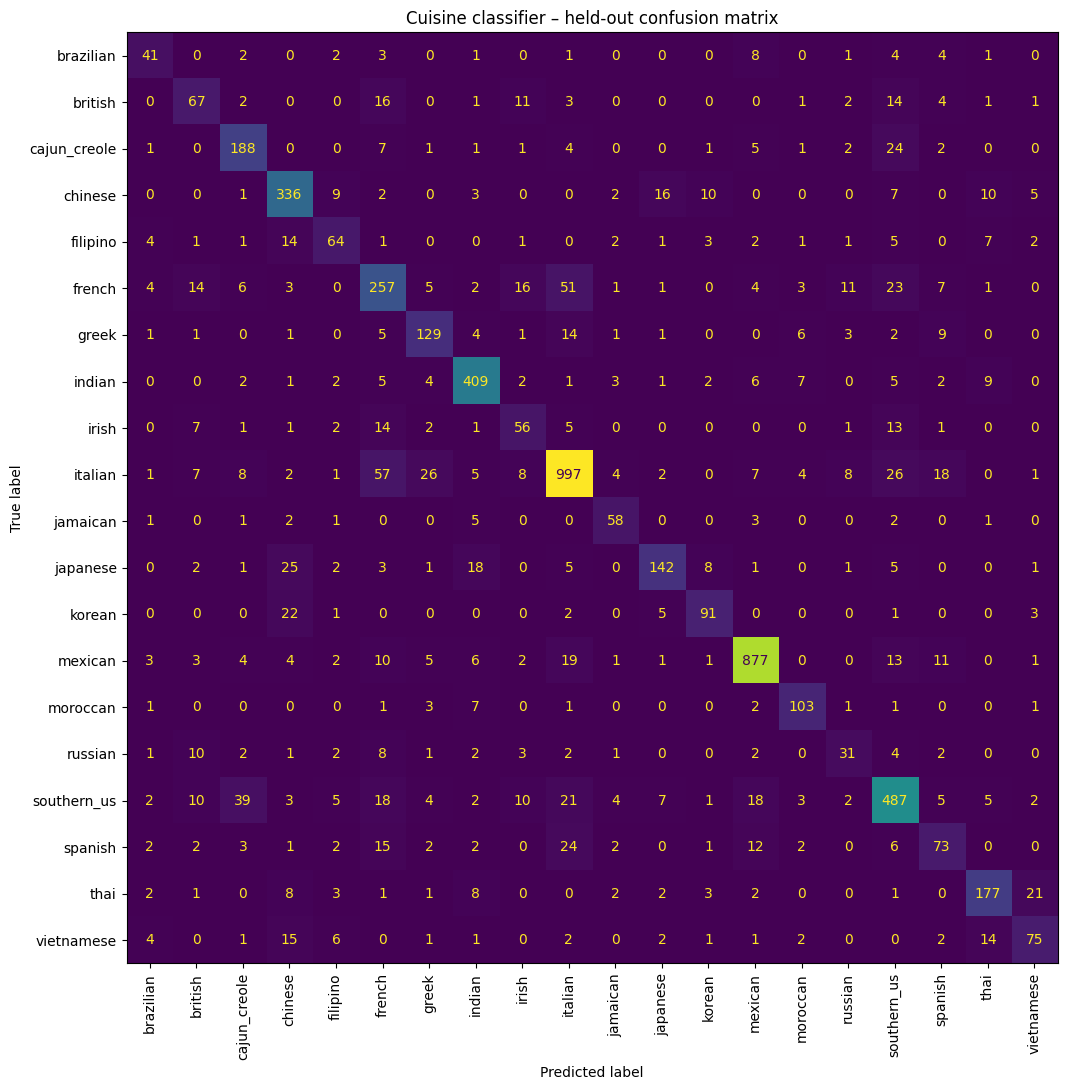

Cuisine example: garlic, tomato, basil, pasta, olive oil => italian
Cuisine example: garam masala, ginger, cumin, turmeric => indian
Cuisine example: miso, nori, rice, mirin => japanese


In [19]:
if cuisine_model is not None and cuisine_test is not None:
    X_test, y_test = cuisine_test
    prediction = cuisine_model.predict(X_test)
    test_acc = float(accuracy_score(y_test, prediction))
    test_macro_f1 = float(f1_score(y_test, prediction, average='macro'))
    check('Cuisine classifier trained', True, f'{len(X_test):,} held-out recipes')
    check('Cuisine classifier predictions valid', len(prediction) == len(y_test),
          'One label per test example')
    print('Held-out Accuracy:', round(test_acc,4))
    print('Held-out Macro-F1:', round(test_macro_f1,4))
    display(cuisine_results)
    print(classification_report(y_test, prediction, zero_division=0))
    labels = sorted(y_test.unique())
    from sklearn.metrics import ConfusionMatrixDisplay
    fig, ax = plt.subplots(figsize=(12,11))
    ConfusionMatrixDisplay.from_predictions(y_test, prediction, labels=labels,
                                           xticks_rotation=90, ax=ax, colorbar=False)
    ax.set_title('Cuisine classifier – held-out confusion matrix')
    plt.tight_layout()
    plt.show()
    for s in ['garlic, tomato, basil, pasta, olive oil',
              'garam masala, ginger, cumin, turmeric',
              'miso, nori, rice, mirin']:
        print('Cuisine example:', s, '=>', predict_cuisine_from_ingredients(s))
else:
    test_acc = None
    test_macro_f1 = None
    check('Cuisine classifier trained', False, 'Attach the dataset with train.json', skip=True)

## 9. Quantitative offline retrieval evaluation

In [20]:
try:
    retrieval_details_test, retrieval_metrics_test = evaluate_semantic_retrieval(
        n_samples=min(100, len(recipes)), ks=(1, 5, 10))
    display(pd.DataFrame([retrieval_metrics_test]))
    check('Semantic retrieval metrics computed',
          all(np.isfinite(v) and 0 <= v <= 1 for v in retrieval_metrics_test.values()),
          str(retrieval_metrics_test))
except Exception as exc:
    retrieval_metrics_test = {}
    check('Semantic retrieval metrics computed', False, str(exc))

try:
    rag_details_test, rag_metrics_test = evaluate_rag_retrieval(top_k=5)
    display(pd.DataFrame([rag_metrics_test]))
    display(rag_details_test)
    check('RAG retrieval metrics computed',
          all(np.isfinite(v) and 0 <= v <= 1 for v in rag_metrics_test.values()),
          str(rag_metrics_test))
except Exception as exc:
    rag_metrics_test = {}
    check('RAG retrieval metrics computed', False, str(exc))

print('Interpretation: recipe HitRate@K here measures recovery of a known recipe from a partial-ingredient query.')
print('RAG HitRate@K uses 4 heuristic term-match questions, not expert-scored answer faithfulness.')

,HitRate@1,HitRate@5,HitRate@10,MRR
0,0.3,0.53,0.6,0.386095


[PASS] Semantic retrieval metrics computed: {'HitRate@1': np.float64(0.3), 'HitRate@5': np.float64(0.53), 'HitRate@10': np.float64(0.6), 'MRR': np.float64(0.38609523809523805)}


,HitRate@5,MRR
0,0.75,0.75


,question,rank,hit@5,reciprocal_rank
0,How can I fix a sauce that is too watery?,1.0,True,1.0
1,My curry is much too spicy. What can I do?,NaN,False,0.0
2,How do I rescue an overly salty dish?,1.0,True,1.0
3,What should I consider when substituting ingredients in baking?,1.0,True,1.0


[PASS] RAG retrieval metrics computed: {'HitRate@5': np.float64(0.75), 'MRR': np.float64(0.75)}
Interpretation: recipe HitRate@K here measures recovery of a known recipe from a partial-ingredient query.
RAG HitRate@K uses 4 heuristic term-match questions, not expert-scored answer faithfulness.


## 10. Final test report + CSV export

In [21]:
results = show_results()
status_counts = results['status'].value_counts().to_dict()

summary = {
    'recipes_indexed': int(len(recipes)),
    'interactions_loaded': int(len(interactions)),
    'faiss_enabled': bool(recipe_index.faiss_enabled),
    'collaborative_filtering_ready': bool(cf_model.ready),
    'cuisine_accuracy': test_acc,
    'cuisine_macro_f1': test_macro_f1,
    **{'recipe_'+str(k):float(v) for k, v in retrieval_metrics_test.items()},
    **{'rag_'+str(k):float(v) for k, v in rag_metrics_test.items()},
}
print('\nTEST SUMMARY:', status_counts)
display(pd.DataFrame([summary]).T.rename(columns={0:'value'}))

out_dir = Path('/kaggle/working') if Path('/kaggle/working').exists() else Path.cwd()
results_path = out_dir / 'souschef_test_results.csv'
summary_path = out_dir / 'souschef_test_metrics.json'
results.to_csv(results_path, index=False)
summary_path.write_text(json.dumps(summary, indent=2))
print('\nSaved report:', results_path)
print('Saved metrics:', summary_path)
if status_counts.get('FAIL', 0):
    print('⚠ Some tests failed. Read the FAIL rows before using the results in your resume.')
elif status_counts.get('WARN', 0):
    print('✅ Core tests finished; warnings identify known limitations.')
else:
    print('✅ All executed tests passed or were explicitly skipped.')

,test,status,detail
0,Food.com recipe CSV connected,PASS,/kaggle/input/datasets/shuyangli94/food-com-recipes-and-user-interactions/RAW_recipes.csv
1,Food.com interactions CSV connected,PASS,/kaggle/input/datasets/shuyangli94/food-com-recipes-and-user-interactions/RAW_interactions.csv
2,Cuisine JSON connected,PASS,/kaggle/input/datasets/kaggle/recipe-ingredients-dataset/train.json
3,Nonempty recipe dataframe,PASS,"5,000 recipes"
4,Nonempty user interactions,PASS,"300,000 interactions"
5,Recipe IDs unique,PASS,duplicates=0
6,Parsed ingredients available,PASS,100.0% have ingredients
7,Recipe text available,PASS,100.0% nonempty
8,Bayesian ratings numeric,PASS,No NaN or infinite Bayesian ratings
9,Embeddings shape matches recipes,PASS,"(5000, 384)"



TEST SUMMARY: {'PASS': 36, 'WARN': 1, 'SKIP': 1}


,value
recipes_indexed,5000
interactions_loaded,300000
faiss_enabled,True
collaborative_filtering_ready,True
cuisine_accuracy,0.776333
cuisine_macro_f1,0.695604
recipe_HitRate@1,0.3
recipe_HitRate@5,0.53
recipe_HitRate@10,0.6
recipe_MRR,0.386095



Saved report: /kaggle/working/souschef_test_results.csv
Saved metrics: /kaggle/working/souschef_test_metrics.json
✅ Core tests finished; warnings identify known limitations.


## How to interpret the outcome

- **PASS:** A functional sanity check passed. It does **not** mean recommendations are always correct.
- **WARN:** A limitation was detected (such as a plural allergy-term exclusion bug or sklearn fallback).
- **FAIL:** A required part of the pipeline failed; inspect that row.
- **SKIP:** Optional part was not run, e.g. LLM generation or missing cuisine data.

**Do not claim allergy safety based on keyword filtering.** Recipe text may have synonyms, hidden allergens, incomplete ingredients, or cross-contact risk. Do not claim RAG answers are hallucination-free based on the four small evaluation questions.

Download `souschef_test_results.csv` and `souschef_test_metrics.json` from the Kaggle **Output** panel after running/saving. You can reuse actual measured numbers in your GitHub README; do not invent accuracy or retrieval scores.